# 01 — Análise Exploratória (EDA)

**Objetivo:** entender a qualidade dos dados, onde está o sinal de fraude e como os dados mudam ao longo do tempo — e, a partir disso, fundamentar as decisões de **pré-processamento**, **métrica** e **validação**.

> **Regra deste notebook:** só o conjunto de **treino (meses 0–5)** é carregado. O teste (meses 6–7) fica intocado até a avaliação final do modelo.

Cada seção segue o formato **Pergunta → Análise → Conclusão**.

1. Visão geral e escolha da métrica
2. Qualidade dos dados
3. Valores ausentes
4. Variáveis binárias
5. Variáveis categóricas
6. Variáveis numéricas
7. Assimetria e correlação
8. Mudança ao longo do tempo (drift)
9. Idade e justiça algorítmica
10. Resumo e decisões

## 0. Configuração

In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- Caminhos portáveis: funciona localmente (VS Code) e no Google Colab ---
EM_COLAB = "google.colab" in sys.modules

if EM_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/fraude-abertura-conta")
else:
    # Localmente o notebook roda de dentro de notebooks/; a raiz do repositório é a pasta acima
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

RAIZ = Path(os.getenv("FRAUDE_RAIZ", RAIZ))  # opcional: sobrescrever por variável de ambiente
DATA_DIR = RAIZ / "data"
FIG_DIR = RAIZ / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# --- Estilo dos gráficos ---
AZUL, LARANJA, VERDE_AGUA, VIOLETA = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
TEXTO_2, CINZA, GRADE = "#52514e", "#8a8986", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": CINZA,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRADE, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.labelcolor": TEXTO_2,
    "xtick.color": TEXTO_2, "ytick.color": TEXTO_2, "font.size": 10, "legend.frameon": False,
})

# Códigos de ausência, segundo o dicionário de dados da base
AUSENTE_MENOS_1 = ["prev_address_months_count", "current_address_months_count", "bank_months_count",
                   "session_length_in_minutes", "device_distinct_emails_8w"]  # -1 = ausente
AUSENTE_NEGATIVO = ["intended_balcon_amount"]                              # qualquer negativo = ausente
COLS_AUSENCIA = AUSENTE_MENOS_1 + AUSENTE_NEGATIVO

LIMIAR_FRAUDES = 30  # abaixo disso, a taxa de fraude de um grupo é considerada pouco confiável

print(f"Ambiente: {'Colab' if EM_COLAB else 'local'} | dados: {DATA_DIR} | figuras: {FIG_DIR}")

Ambiente: local | dados: c:\Users\joaog\Documents\Projetos\fraude-abertura-conta\data | figuras: c:\Users\joaog\Documents\Projetos\fraude-abertura-conta\reports\figures


**Funções auxiliares.** Usadas em várias seções:

- `taxa_por_grupo`: para cada valor de uma coluna, conta linhas e fraudes e calcula a taxa de fraude com **intervalo de confiança de 95% (Wilson)**. O intervalo mostra o quanto a taxa é incerta: em grupos com poucas fraudes ele fica largo, o que impede tirar conclusões de amostras pequenas. O método de Wilson é preferível à aproximação normal ($p \pm 1{,}96\sqrt{p(1-p)/n}$) quando a proporção é pequena, como aqui.
- `marcar_ausentes`: devolve uma cópia em que os códigos de ausência viram `NaN`, para que não distorçam médias, quantis e correlações.
- `plot_taxa` e `salvar`: gráfico padrão de taxa de fraude com IC e gravação em `reports/figures/`.

In [2]:
def taxa_por_grupo(df, coluna, alvo="fraud_bool", z=1.96):
    """Taxa de fraude (%) por valor de `coluna`, com contagens e IC 95% de Wilson."""
    g = df.groupby(coluna, observed=True)[alvo].agg(qtd="size", fraudes="sum")
    n, p = g["qtd"], g["fraudes"] / g["qtd"]
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margem = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    g["% fraude"] = 100 * p
    g["IC95 inf"] = 100 * (centro - margem)
    g["IC95 sup"] = 100 * (centro + margem)
    return g


def marcar_ausentes(df):
    """Cópia do DataFrame com os códigos de ausência substituídos por NaN."""
    out = df.copy()
    for c in AUSENTE_MENOS_1:
        out[c] = out[c].where(out[c] != -1)
    for c in AUSENTE_NEGATIVO:
        out[c] = out[c].where(out[c] >= 0)
    return out


def plot_taxa(ax, tabela, titulo, taxa_base, rotulos=None, rotacao=0, cor=AZUL):
    """Barras com a taxa de fraude por grupo, barras de erro (IC 95%) e a média como referência."""
    x = np.arange(len(tabela))
    erro = [tabela["% fraude"] - tabela["IC95 inf"], tabela["IC95 sup"] - tabela["% fraude"]]
    ax.bar(x, tabela["% fraude"], color=cor, width=0.6)
    ax.errorbar(x, tabela["% fraude"], yerr=erro, fmt="none", ecolor=TEXTO_2, capsize=3, lw=1)
    ax.axhline(taxa_base, color=CINZA, ls="--", lw=1.2)
    rot = rotulos if rotulos is not None else [str(i) for i in tabela.index]
    ax.set_xticks(x, rot, rotation=rotacao, ha="right" if rotacao else "center")
    ax.set_title(titulo)
    ax.set_ylabel("% fraude")


def salvar(fig, nome):
    fig.savefig(FIG_DIR / f"{nome}.png")

## 1. Visão geral e escolha da métrica

**Pergunta:** qual o tamanho da base, quão rara é a fraude e, por consequência, que métrica faz sentido?

In [3]:
treino = pd.read_parquet(DATA_DIR / "train.parquet")
assert treino["month"].between(0, 5).all(), "train.parquet deveria conter apenas os meses 0–5"

TAXA_BASE = 100 * treino["fraud_bool"].mean()

print(f"{treino.shape[0]:,} linhas x {treino.shape[1]} colunas")
print(f"Fraudes: {treino['fraud_bool'].sum():,} ({TAXA_BASE:.2f}%)")
print(f"Acurácia de um modelo que sempre responde 'não é fraude': {100 - TAXA_BASE:.2f}%")

794,989 linhas x 32 colunas
Fraudes: 8,151 (1.03%)
Acurácia de um modelo que sempre responde 'não é fraude': 98.97%


**O que significa operar a 5% de FPR?** A conta abaixo traduz a métrica em impacto operacional. O recall de 55% é **hipotético**, só para ilustrar a ordem de grandeza.

In [4]:
N = 10_000
FPR_ALVO = 0.05
RECALL_EXEMPLO = 0.55  # hipotético

fraudes = N * TAXA_BASE / 100
legitimos = N - fraudes
falsos_alertas = FPR_ALVO * legitimos
fraudes_pegas = RECALL_EXEMPLO * fraudes
precisao = fraudes_pegas / (fraudes_pegas + falsos_alertas)

print(f"A cada {N:,} pedidos: ~{legitimos:,.0f} legítimos e ~{fraudes:,.0f} fraudes")
print(f"Operando a {FPR_ALVO:.0%} de FPR: ~{falsos_alertas:,.0f} clientes legítimos barrados")
print(f"Com recall de {RECALL_EXEMPLO:.0%}: ~{fraudes_pegas:,.0f} fraudes pegas")
print(f"Precisão no ponto de corte: ~{precisao:.1%} (≈ 1 fraude real a cada {1 / precisao:.0f} contas barradas)")

A cada 10,000 pedidos: ~9,897 legítimos e ~103 fraudes
Operando a 5% de FPR: ~495 clientes legítimos barrados
Com recall de 55%: ~56 fraudes pegas
Precisão no ponto de corte: ~10.2% (≈ 1 fraude real a cada 10 contas barradas)


**Conclusão:**

- A fraude é **1,03%** do treino (8.151 casos). Acurácia não serve: responder "nunca é fraude" já acerta 98,97% sem detectar nada.
- Métricas adotadas:
  - **Recall a 5% de FPR (principal):** reflete a restrição de negócio — o banco tolera barrar no máximo 5% dos clientes legítimos; dentro desse limite, quantas fraudes pegamos? É também o protocolo de avaliação do artigo da base.
  - **PR-AUC (Average Precision):** foca na classe rara e é sensível aos falsos positivos. Com ~1% de positivos, a ROC AUC pode parecer alta mesmo com precisão baixa.
  - **ROC AUC:** independente de limiar; útil para comparar modelos entre si e com a literatura.
- Mesmo um bom modelo terá **precisão baixa** no ponto de operação: no exemplo, ~495 clientes legítimos barrados a cada 10 mil pedidos, para ~56 fraudes pegas (≈ 1 fraude real a cada 10 contas barradas). Na prática, um sistema assim alimenta uma fila de revisão manual em vez de bloquear clientes automaticamente.

## 2. Qualidade dos dados

**Pergunta:** há valores impossíveis, códigos de ausência ou colunas sem informação?

In [5]:
treino.describe().T

,count,mean,std,min,25%,50%,75%,max
fraud_bool,"794,989.00",0.01,0.10,0.00,0.00,0.00,0.00,1.00
income,"794,989.00",0.55,0.29,0.10,0.30,0.60,0.80,0.90
name_email_similarity,"794,989.00",0.50,0.29,0.00,0.23,0.50,0.76,1.00
prev_address_months_count,"794,989.00",16.32,43.80,-1.00,-1.00,-1.00,12.00,377.00
current_address_months_count,"794,989.00",88.10,89.89,-1.00,20.00,53.00,132.00,425.00
customer_age,"794,989.00",33.66,12.09,10.00,20.00,30.00,40.00,90.00
days_since_request,"794,989.00",1.07,5.38,0.00,0.01,0.02,0.03,76.58
intended_balcon_amount,"794,989.00",8.91,20.43,-15.53,-1.17,-0.82,7.64,112.96
zip_count_4w,"794,989.00","1,681.88","1,036.62",1.00,966.00,"1,361.00","2,097.00","6,700.00"
velocity_6h,"794,989.00","6,148.45","3,013.66",-130.46,"3,971.40","5,961.19","8,113.53","16,715.57"


In [6]:
numericas = treino.select_dtypes("number").columns.drop(["fraud_bool", "month"]).tolist()
categoricas = treino.select_dtypes(exclude="number").columns.tolist()
constantes = [c for c in treino.columns if treino[c].nunique() == 1]

print("Colunas categóricas:", categoricas)
print("Colunas constantes:", constantes)
print("Valores NaN explícitos:", int(treino.isna().sum().sum()))

negativos = (treino[numericas] < 0).sum()
negativos = negativos[negativos > 0].sort_values(ascending=False)
pd.DataFrame({
    "qtd negativos": negativos,
    "% linhas": 100 * negativos / len(treino),
    "mínimo": treino[negativos.index].min(),
})

Colunas categóricas: ['payment_type', 'employment_status', 'housing_status', 'source', 'device_os']
Colunas constantes: ['device_fraud_count']
Valores NaN explícitos: 0


,qtd negativos,% linhas,mínimo
intended_balcon_amount,585908,73.70,-15.53
prev_address_months_count,568423,71.50,-1.00
bank_months_count,199549,25.10,-1.00
credit_risk_score,13435,1.69,-170.00
current_address_months_count,3027,0.38,-1.00
session_length_in_minutes,1513,0.19,-1.00
device_distinct_emails_8w,309,0.04,-1.00
velocity_6h,20,0.00,-130.46


**Conclusão:**

- Não há `NaN` explícitos: as ausências vêm **codificadas como valores negativos**.
- Os negativos se dividem em três grupos:
  1. **Códigos de ausência** (segundo o dicionário de dados): `-1` em `prev_address_months_count` (71,5% das linhas), `bank_months_count` (25,1%), `current_address_months_count` (0,38%), `session_length_in_minutes` (0,19%) e `device_distinct_emails_8w` (0,04%); e **qualquer** negativo em `intended_balcon_amount` (73,7%).
  2. **Valores legítimos:** `credit_risk_score` (1,69% das linhas, mínimo -170) — a escala do score inclui negativos.
  3. **Valores impossíveis:** `velocity_6h` tem **20 linhas** negativas (mínimo -130) — uma velocidade de pedidos não pode ser negativa. Provavelmente é um artefato da geração sintética da base (CTGAN). São pouquíssimas linhas, mas o tratamento é simples: **clipar em 0**.
- `device_fraud_count` é **constante** no treino → será removida.
- Há 5 colunas categóricas (texto): `payment_type`, `employment_status`, `housing_status`, `source`, `device_os`.

## 3. Valores ausentes

**Pergunta:** a ausência de uma informação está associada à fraude? Se estiver, a ausência é um sinal em si — e preenchê-la pela média apagaria esse sinal.

In [7]:
linhas = []
for c in COLS_AUSENCIA:
    t = taxa_por_grupo(treino.assign(ausente=treino[c] < 0), "ausente").reindex([False, True])
    linhas.append({
        "coluna": c,
        "% ausente": 100 * (treino[c] < 0).mean(),
        "fraudes (ausente)": t.loc[True, "fraudes"],
        "% fraude (ausente)": t.loc[True, "% fraude"],
        "% fraude (presente)": t.loc[False, "% fraude"],
        "_ic_aus": (t.loc[True, "IC95 inf"], t.loc[True, "IC95 sup"]),
        "_ic_pres": (t.loc[False, "IC95 inf"], t.loc[False, "IC95 sup"]),
    })
ausencia = pd.DataFrame(linhas).set_index("coluna")
ausencia["razão"] = ausencia["% fraude (ausente)"] / ausencia["% fraude (presente)"]
ausencia.drop(columns=["_ic_aus", "_ic_pres"])

,% ausente,fraudes (ausente),% fraude (ausente),% fraude (presente),razão
coluna,,,,,
prev_address_months_count,71.50,7517,1.32,0.28,4.73
current_address_months_count,0.38,9,0.30,1.03,0.29
bank_months_count,25.10,3064,1.54,0.85,1.80
session_length_in_minutes,0.19,13,0.86,1.03,0.84
device_distinct_emails_8w,0.04,3,0.97,1.03,0.95
intended_balcon_amount,73.70,7160,1.22,0.47,2.58


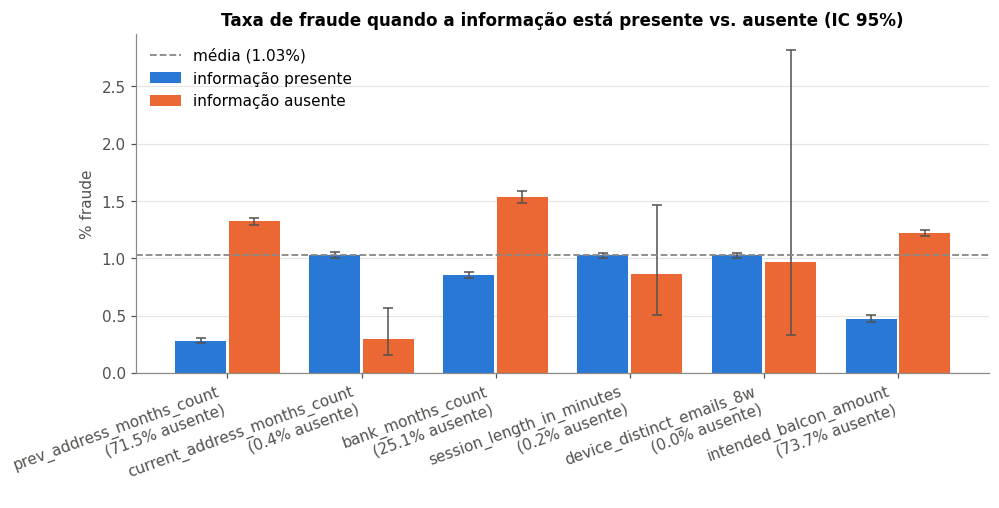

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(ausencia))
for desloc, col_taxa, col_ic, cor, nome in [(-0.2, "% fraude (presente)", "_ic_pres", AZUL, "informação presente"),
                                            (0.2, "% fraude (ausente)", "_ic_aus", LARANJA, "informação ausente")]:
    taxa = ausencia[col_taxa]
    inf = ausencia[col_ic].str[0]
    sup = ausencia[col_ic].str[1]
    ax.bar(x + desloc, taxa, width=0.38, color=cor, label=nome)
    ax.errorbar(x + desloc, taxa, yerr=[taxa - inf, sup - taxa], fmt="none", ecolor=TEXTO_2, capsize=3, lw=1)
ax.axhline(TAXA_BASE, color=CINZA, ls="--", lw=1.2, label=f"média ({TAXA_BASE:.2f}%)")
ax.set_xticks(x, [f"{c}\n({p:.1f}% ausente)" for c, p in ausencia["% ausente"].items()], rotation=20, ha="right")
ax.set_ylabel("% fraude")
ax.set_title("Taxa de fraude quando a informação está presente vs. ausente (IC 95%)")
ax.legend()
salvar(fig, "03_ausencia_vs_fraude")
plt.show()

**Conclusão:**

| Atributo | % ausente | Fraude se ausente | Fraude se presente | Razão |
|---|---|---|---|---|
| `prev_address_months_count` | 71,5% | 1,32% | 0,28% | **~4,7×** |
| `intended_balcon_amount` | 73,7% | 1,22% | 0,47% | ~2,6× |
| `bank_months_count` | 25,1% | 1,54% | 0,85% | ~1,8× |

- Nessas três colunas, a ausência está fortemente associada à fraude, e os intervalos de confiança não se sobrepõem.
- Em `current_address_months_count`, `session_length_in_minutes` e `device_distinct_emails_8w` a ausência é rara (≤ 0,4% das linhas, poucas fraudes envolvidas): os intervalos são largos e as diferenças **não são conclusivas**.
- **Decisão de pré-processamento:**
  - **Modelos de árvore:** mantêm o código negativo como valor próprio — a árvore aprende sozinha a separar "ausente" de "presente".
  - **Modelos lineares:** criar um indicador `<coluna>_ausente` (0/1) **e** substituir o valor original pela mediana dos valores válidos. Sem a substituição, o modelo continuaria multiplicando o -1 (ou -15,5) pelo peso da variável. A mediana é calculada **só nos dados de treino de cada fold**, dentro do pipeline, para não vazar informação da validação.

## 4. Variáveis binárias

**Pergunta:** as variáveis 0/1 (e-mail gratuito, telefone válido, sessão mantida etc.) separam fraude de não-fraude?

In [9]:
binarias = [c for c in numericas if c not in constantes and set(treino[c].unique()) <= {0, 1}]

resumo_bin = []
for c in binarias:
    t = taxa_por_grupo(treino, c).reindex([0, 1])
    resumo_bin.append({
        "coluna": c,
        "% linhas com 1": 100 * treino[c].mean(),
        "% fraude se 0": t.loc[0, "% fraude"],
        "% fraude se 1": t.loc[1, "% fraude"],
        "fraudes (menor grupo)": t["fraudes"].min(),
    })
resumo_bin = pd.DataFrame(resumo_bin).set_index("coluna")
resumo_bin["razão (1 / 0)"] = resumo_bin["% fraude se 1"] / resumo_bin["% fraude se 0"]
resumo_bin.sort_values("razão (1 / 0)", ascending=False)

,% linhas com 1,% fraude se 0,% fraude se 1,fraudes (menor grupo),razão (1 / 0)
coluna,,,,,
foreign_request,2.60,1.00,2.00,414,2.01
email_is_free,54.19,0.74,1.27,2685,1.72
phone_mobile_valid,88.51,1.45,0.97,1320,0.67
phone_home_valid,40.48,1.29,0.64,2046,0.49
keep_alive_session,56.91,1.58,0.60,2730,0.38
has_other_cards,22.42,1.20,0.41,722,0.34


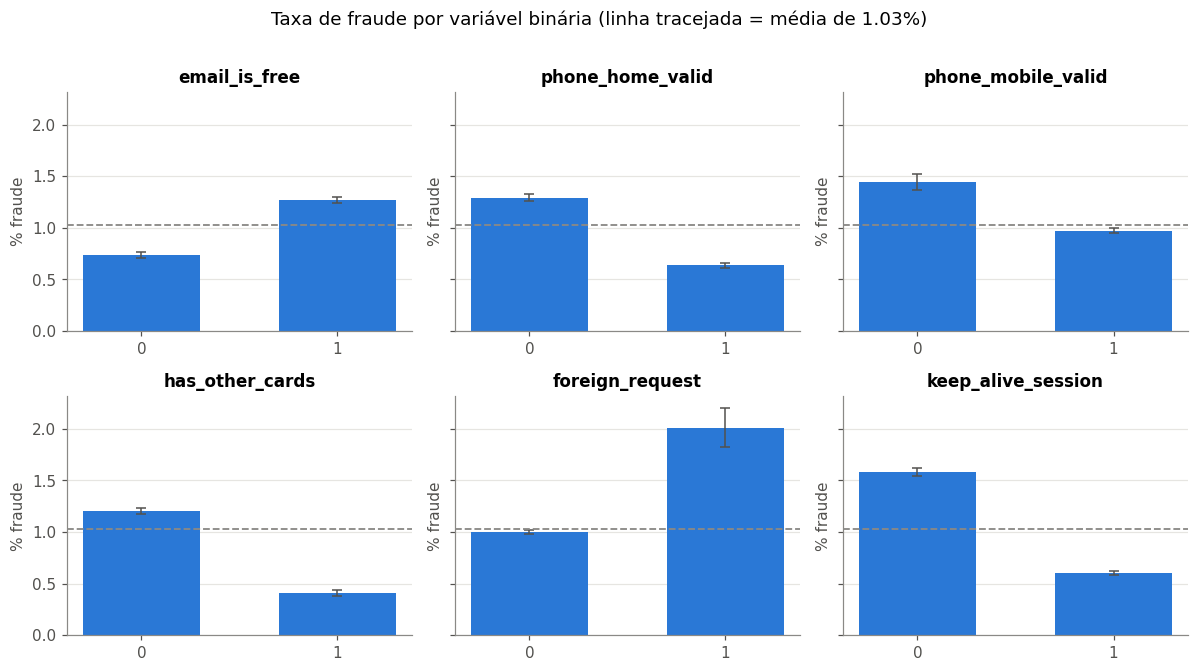

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
for ax, c in zip(axes.flat, binarias):
    plot_taxa(ax, taxa_por_grupo(treino, c), c, TAXA_BASE, rotulos=["0", "1"])
for ax in axes.flat[len(binarias):]:
    ax.set_visible(False)
fig.suptitle(f"Taxa de fraude por variável binária (linha tracejada = média de {TAXA_BASE:.2f}%)", y=1.01)
fig.tight_layout()
salvar(fig, "04_binarias_vs_fraude")
plt.show()

**Conclusão:**

- **As seis binárias carregam sinal**, e todas com amostra grande (o menor grupo tem 414 fraudes), então as diferenças são confiáveis:

| Mais fraude quando... | Taxa | Contra | Razão |
|---|---|---|---|
| `has_other_cards = 0` (não tem outros cartões no banco) | 1,20% | 0,41% | ~2,9× |
| `keep_alive_session = 0` (não manteve a sessão ativa) | 1,58% | 0,60% | ~2,6× |
| `foreign_request = 1` (pedido feito do exterior) | 2,00% | 1,00% | ~2,0× |
| `phone_home_valid = 0` (telefone fixo inválido) | 1,29% | 0,64% | ~2,0× |
| `email_is_free = 1` (e-mail gratuito) | 1,27% | 0,74% | ~1,7× |
| `phone_mobile_valid = 0` (celular inválido) | 1,45% | 0,97% | ~1,5× |

- O padrão é coerente: a fraude aparece mais em pedidos com **menos vínculos verificáveis** — sem outro produto no banco, sem telefone válido, com e-mail gratuito (fácil de criar em série).
- **Decisão:** as binárias já estão prontas para qualquer modelo (0/1); não precisam de transformação.

## 5. Variáveis categóricas

**Pergunta:** alguma categoria concentra fraude? E quais categorias têm fraudes de menos para uma taxa confiável (menos de 30 casos)?

In [11]:
for c in categoricas:
    t = taxa_por_grupo(treino, c).sort_values("% fraude", ascending=False)
    t["confiável"] = t["fraudes"] >= LIMIAR_FRAUDES
    print(f"\n=== {c}")
    print(t.round(2).to_string())


=== payment_type
                 qtd  fraudes  % fraude  IC95 inf  IC95 sup  confiável
payment_type                                                          
AC            198579     3134      1.58      1.52      1.63       True
AB            288182     2996      1.04      1.00      1.08       True
AD             99060      972      0.98      0.92      1.04       True
AA            208920     1048      0.50      0.47      0.53       True
AE               248        1      0.40      0.07      2.25      False

=== employment_status
                      qtd  fraudes  % fraude  IC95 inf  IC95 sup  confiável
employment_status                                                          
CC                  31247      730      2.34      2.17      2.51       True
CG                    372        5      1.34      0.58      3.11      False
CA                 571543     6486      1.13      1.11      1.16       True
CB                 115450      737      0.64      0.59      0.69       True
CD    

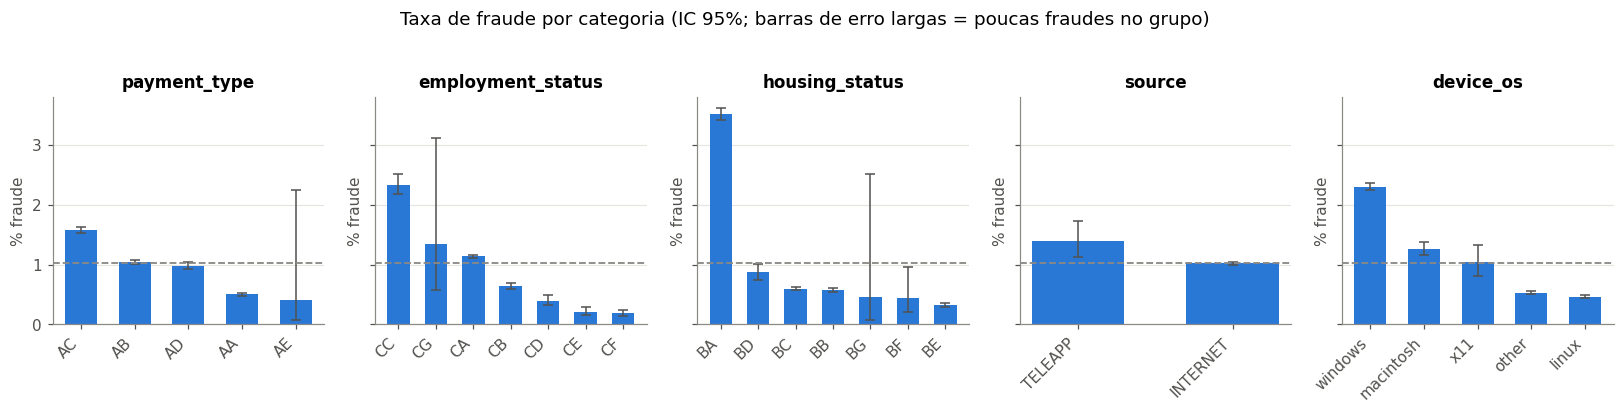

In [12]:
fig, axes = plt.subplots(1, len(categoricas), figsize=(15, 3.6), sharey=True)
for ax, c in zip(axes, categoricas):
    t = taxa_por_grupo(treino, c).sort_values("% fraude", ascending=False)
    plot_taxa(ax, t, c, TAXA_BASE, rotacao=45)
fig.suptitle("Taxa de fraude por categoria (IC 95%; barras de erro largas = poucas fraudes no grupo)", y=1.03)
fig.tight_layout()
salvar(fig, "05_categoricas_vs_fraude")
plt.show()

**Conclusão:**

- **Sinais fortes e confiáveis** (categorias grandes, taxa bem acima da média de 1,03%):
  - `housing_status = BA`: 3,52% (~130 mil linhas, **~3,4×** a média)
  - `employment_status = CC`: 2,34% (~31 mil linhas)
  - `device_os = windows`: 2,30% (~213 mil linhas)
  - `payment_type = AC`: 1,58% (~199 mil linhas)
- Também há categorias com fraude bem **abaixo** da média, o que é sinal tanto quanto o contrário: `employment_status = CE/CF` (~0,2%) e `housing_status = BE` (0,32%).
- `source = TELEAPP` (~5,7 mil linhas, 80 fraudes): 1,39% contra 1,02% de `INTERNET` — os intervalos não se sobrepõem, mas a diferença é pequena.
- **Categorias raras**, com taxa não confiável: `payment_type = AE` (1 fraude), `employment_status = CG` (5), `housing_status = BG` (1) e `BF` (6).
- Os códigos das categorias são anônimos (BA, CC...), então não dá para interpretar seu significado — mas o modelo só precisa que o padrão seja estável.
- **Decisão de pré-processamento:**
  - **Modelos lineares:** agrupar categorias raras em `"outros"` e aplicar **one-hot encoding** (são poucas categorias por coluna).
  - **LightGBM:** suporte nativo a categóricas; o mínimo de amostras por folha já protege contra categorias raras.

## 6. Variáveis numéricas

**Pergunta:** como a taxa de fraude varia ao longo dos valores de cada variável numérica? A relação é crescente, decrescente, em "U" — ou não existe?

Variáveis **discretas** são analisadas valor a valor; as **contínuas**, por **decis** (10 faixas com o mesmo número de linhas). Os códigos de ausência ficam de fora aqui — já foram analisados na seção 3.

Valores distintos de proposed_credit_limit: [190.0, 200.0, 210.0, 490.0, 500.0, 510.0, 990.0, 1000.0, 1500.0, 1900.0, 2000.0, 2100.0]


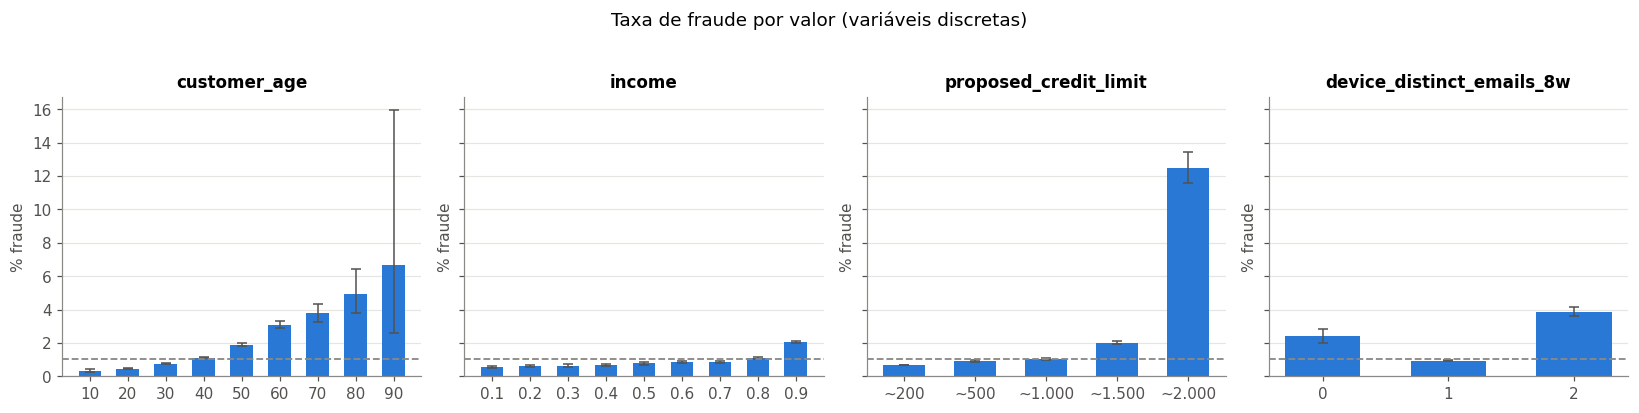

In [13]:
# Cópia com os códigos de ausência como NaN (seção 3) e velocity_6h sem negativos impossíveis (seção 2)
treino_nan = marcar_ausentes(treino)
treino_nan["velocity_6h"] = treino_nan["velocity_6h"].clip(lower=0)

limites = [0, 300, 750, 1250, 1750, np.inf]
rotulos_limite = ["~200", "~500", "~1.000", "~1.500", "~2.000"]
discretas = {
    "customer_age": treino["customer_age"],
    "income": treino["income"].round(1),
    "proposed_credit_limit": pd.cut(treino["proposed_credit_limit"], limites, labels=rotulos_limite),
    "device_distinct_emails_8w": treino_nan["device_distinct_emails_8w"].astype("Int64"),  # só 0, 1 ou 2 (ausentes excluídos)
}
print("Valores distintos de proposed_credit_limit:", sorted(treino["proposed_credit_limit"].unique().tolist()))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (nome, serie) in zip(axes, discretas.items()):
    t = taxa_por_grupo(treino.assign(_grupo=serie), "_grupo")
    plot_taxa(ax, t, nome, TAXA_BASE)
fig.suptitle("Taxa de fraude por valor (variáveis discretas)", y=1.03)
fig.tight_layout()
salvar(fig, "06a_discretas_vs_fraude")
plt.show()

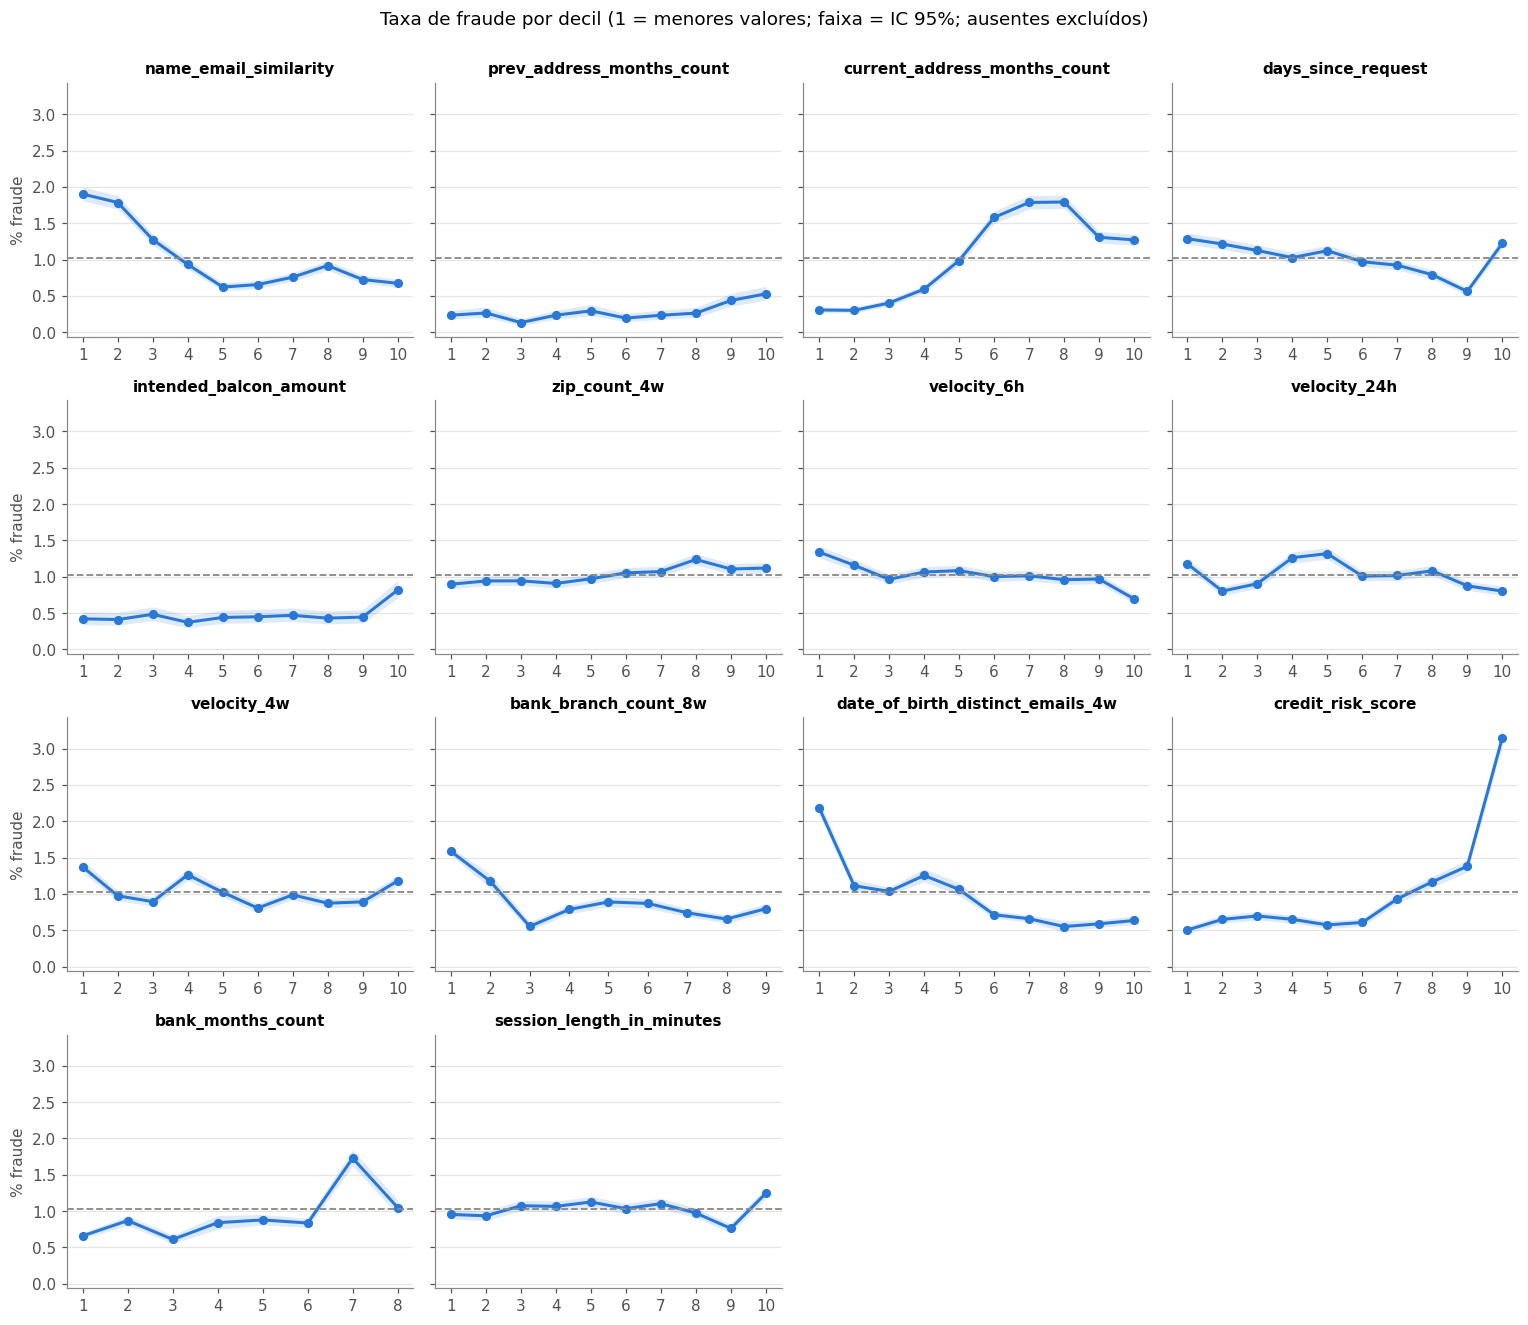

,razão maior/menor taxa entre decis
credit_risk_score,6.25
current_address_months_count,5.94
date_of_birth_distinct_emails_4w,3.97
prev_address_months_count,3.96
name_email_similarity,3.05
bank_branch_count_8w,2.87
bank_months_count,2.84
days_since_request,2.29
intended_balcon_amount,2.19
velocity_6h,1.93


In [14]:
continuas = [c for c in numericas if c not in binarias + list(discretas) + constantes]

fig, axes = plt.subplots(4, 4, figsize=(14, 12), sharey=True)
amplitude = {}
for ax, c in zip(axes.flat, continuas):
    validos = treino_nan[[c, "fraud_bool"]].dropna()
    validos["decil"] = pd.qcut(validos[c], 10, labels=False, duplicates="drop") + 1
    t = taxa_por_grupo(validos, "decil")
    amplitude[c] = t["% fraude"].max() / max(t["% fraude"].min(), 1e-9)
    ax.plot(t.index, t["% fraude"], marker="o", ms=5, lw=2, color=AZUL)
    ax.fill_between(t.index, t["IC95 inf"], t["IC95 sup"], color=AZUL, alpha=0.15, lw=0)
    ax.axhline(TAXA_BASE, color=CINZA, ls="--", lw=1.2)
    ax.set_title(c, fontsize=10)
    ax.set_xticks(t.index)
for ax in axes.flat[len(continuas):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("% fraude")
fig.suptitle("Taxa de fraude por decil (1 = menores valores; faixa = IC 95%; ausentes excluídos)", y=1.0)
fig.tight_layout()
salvar(fig, "06b_continuas_decis_vs_fraude")
plt.show()

# Quanto a taxa de fraude varia entre o pior e o melhor decil: um ranking simples de sinal univariado
pd.Series(amplitude, name="razão maior/menor taxa entre decis").sort_values(ascending=False).to_frame()

**Conclusão:**

**Discretas:**
- **`proposed_credit_limit` é o sinal univariado mais forte da base:** pedidos com limite proposto de ~2.000 têm **~12,5%** de fraude, cerca de **12×** a média. A faixa de ~1.500 fica em ~2%, e as demais perto ou abaixo da média. Uma hipótese é que fraudadores buscam (ou apresentam perfis que recebem) limites altos.
- **`customer_age` cresce de forma monotônica:** de menos de 0,5% abaixo dos 30 anos para ~3–5% entre 60 e 80 anos. O grupo de 90 anos tem intervalo de confiança muito largo (poucas pessoas).
- **`income`:** quase plana até 0,8, com salto na faixa mais alta (0,9 → ~2%).
- **`device_distinct_emails_8w`:** o caso normal (1 e-mail por dispositivo) fica abaixo da média; **0** (~2,4%) e **2** e-mails (~3,9%) concentram fraude — um mesmo dispositivo usado com vários e-mails é sinal clássico de fraude.

**Contínuas** (ordenadas pela razão entre o decil com mais e o com menos fraude):
- **`credit_risk_score` (~6×):** plana até o 6º decil (~0,5–0,7%) e sobe forte no topo (~3,1% no último decil). O score mais alto está associado a **mais** fraude — e ele é correlacionado com `proposed_credit_limit` (seção 7), o que é coerente com o achado acima.
- **`current_address_months_count` (~6×):** quem mora há **menos** tempo no endereço frauda **menos** (~0,3%), e o pico fica nos decis 6–8 (~1,8%). Isso contraria a intuição — provavelmente reflete a **idade**: pessoas mais velhas moram há mais tempo no mesmo endereço e, nesta base, fraudam mais.
- **`date_of_birth_distinct_emails_4w` (~4×):** o 1º decil (poucos e-mails para a mesma data de nascimento) tem ~2,2% de fraude. Também se relaciona com a idade (correlação de ~-0,4 com `customer_age`).
- **`name_email_similarity` (~3×):** e-mail **pouco parecido com o nome** (decis 1–2) → ~1,8–1,9% de fraude, quase o dobro da média.
- `bank_branch_count_8w`, `bank_months_count`, `days_since_request` e `intended_balcon_amount`: sinal moderado (2–3×), vários com formas **não monotônicas** (picos isolados, "U").
- Velocidades, `zip_count_4w` e `session_length_in_minutes`: sinal fraco (< 2×).

**Decisões:**
- Várias relações são **não lineares** (picos, "U", saltos no topo). Modelos de árvore as capturam naturalmente; um modelo linear não — mais um argumento para o **gradient boosting** como modelo principal, com a regressão logística servindo só de régua.
- A idade parece "contaminar" outras variáveis (endereço atual, e-mails por data de nascimento). Análise univariada não separa esses efeitos; a **interpretabilidade com SHAP**, no modelo final, vai mostrar o efeito de cada variável **descontando as demais**.

## 7. Assimetria e correlação

**Pergunta:** há variáveis com cauda longa ou fortemente correlacionadas entre si?

Isso importa sobretudo para o **baseline linear** (regressão logística): caudas longas pedem uma transformação como `log1p` antes da padronização, e variáveis muito correlacionadas tornam os coeficientes instáveis e difíceis de interpretar. Modelos de árvore são pouco afetados pelas duas coisas.

Usamos a correlação de **Spearman** (baseada em postos), que capta relações monotônicas mesmo não lineares e é menos sensível a valores extremos que a de Pearson.

In [15]:
assimetria = treino_nan[continuas].skew().sort_values(key=abs, ascending=False)
pd.DataFrame({
    "assimetria": assimetria,
    "cauda longa (|assimetria| > 2)": assimetria.abs() > 2,
    "mínimo": treino_nan[assimetria.index].min(),
})

,assimetria,cauda longa (|assimetria| > 2),mínimo
days_since_request,9.12,True,0.00
session_length_in_minutes,3.26,True,0.00
bank_branch_count_8w,2.69,True,0.00
prev_address_months_count,2.33,True,5.00
current_address_months_count,1.38,False,0.00
zip_count_4w,1.38,False,1.00
intended_balcon_amount,1.31,False,0.00
date_of_birth_distinct_emails_4w,0.60,False,0.00
velocity_6h,0.41,False,0.00
velocity_24h,0.33,False,"1,324.79"


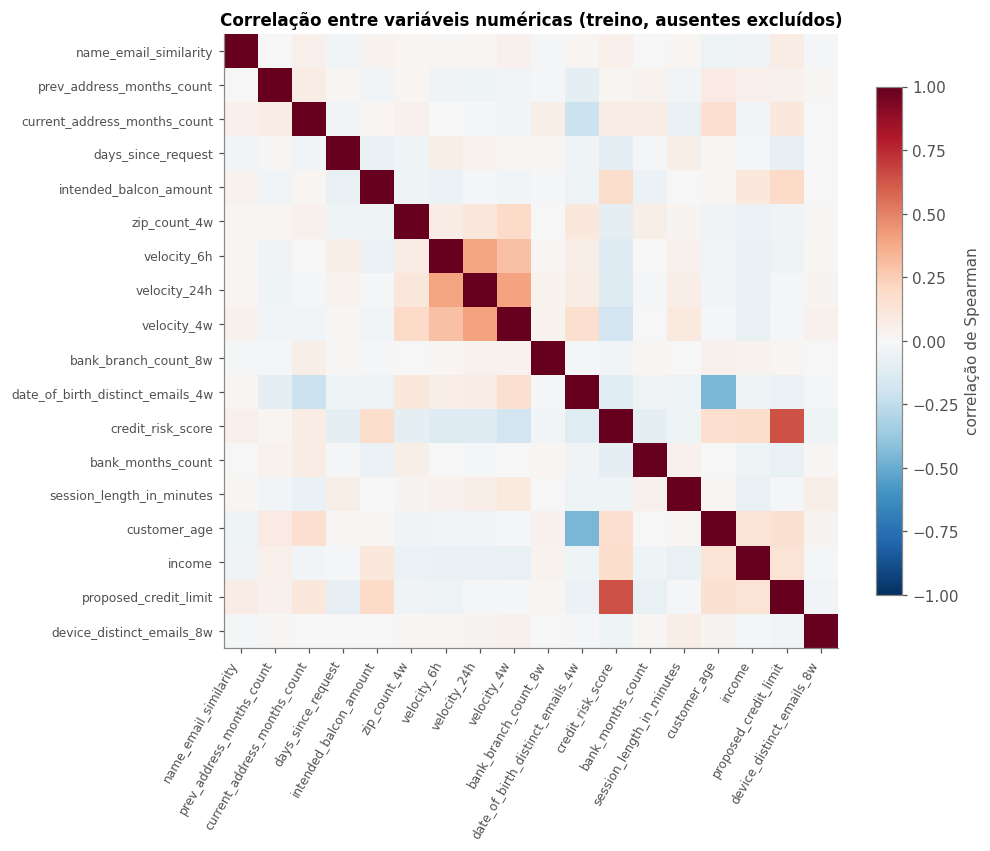

Pares com |correlação| >= 0,5:
credit_risk_score  proposed_credit_limit   0.63


In [16]:
cols_corr = continuas + list(discretas)  # proposed_credit_limit entra com o valor original
corr = treino_nan[cols_corr].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols_corr)), cols_corr, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(cols_corr)), cols_corr, fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="correlação de Spearman")
ax.set_title("Correlação entre variáveis numéricas (treino, ausentes excluídos)")
salvar(fig, "07_correlacao_spearman")
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
pares = pares[pares.abs() >= 0.5].sort_values(key=abs, ascending=False)
print("Pares com |correlação| >= 0,5:")
print(pares.round(2).to_string() if len(pares) else "nenhum")

**Conclusão:**

- **Cauda longa** (|assimetria| > 2): `days_since_request` (9,1), `session_length_in_minutes` (3,3), `bank_branch_count_8w` (2,7) e `prev_address_months_count` (2,3). Todas têm mínimo ≥ 0 depois de remover os códigos de ausência, então `log1p` pode ser aplicado com segurança.
- **Correlação forte** (|ρ| ≥ 0,5): só um par — `credit_risk_score` × `proposed_credit_limit` (**0,63**), o que faz sentido de negócio: o limite oferecido depende do score.
- **Correlações moderadas** (~0,3–0,4): entre as três velocidades (`velocity_6h`, `24h`, `4w`) e entre `date_of_birth_distinct_emails_4w` e `customer_age` (negativa, ~-0,4). As velocidades **não são redundantes** — medem janelas de tempo diferentes.
- **Decisões:**
  - **Modelos lineares:** `log1p` + padronização nas quatro variáveis de cauda longa; regularização L2 para lidar com a correlação moderada. Nenhuma variável é removida.
  - Ao interpretar o modelo, lembrar que `credit_risk_score` e `proposed_credit_limit` "dividem" parte do mesmo sinal.
  - **Modelos de árvore:** nenhuma transformação necessária (são invariantes a transformações monotônicas).

## 8. Mudança ao longo do tempo (drift)

**Pergunta:** a taxa de fraude e a distribuição das variáveis são estáveis mês a mês? Se não forem, uma validação cruzada aleatória (que embaralha os meses) daria uma estimativa otimista do desempenho.

In [17]:
cols_tempo = ["velocity_6h", "velocity_24h", "velocity_4w", "credit_risk_score"]

por_mes = taxa_por_grupo(treino, "month")[["qtd", "fraudes", "% fraude", "IC95 inf", "IC95 sup"]]
medianas = treino_nan.groupby("month")[cols_tempo].median()
por_mes.join(medianas.add_prefix("mediana "))

,qtd,fraudes,% fraude,IC95 inf,IC95 sup,mediana velocity_6h,mediana velocity_24h,mediana velocity_4w,mediana credit_risk_score
month,,,,,,,,,
0,132440,1500,1.13,1.08,1.19,"7,623.05","5,950.37","6,343.59",106.00
1,127620,1198,0.94,0.89,0.99,"6,482.07","5,340.66","5,446.32",99.00
2,136979,1198,0.87,0.83,0.93,"6,164.51","5,044.82","5,462.17",106.00
3,150936,1392,0.92,0.88,0.97,"5,940.10","4,969.45","4,909.93",138.00
4,127691,1452,1.14,1.08,1.20,"5,242.32","4,662.34","4,695.66",130.00
5,119323,1411,1.18,1.12,1.25,"4,620.62","4,215.33","4,267.07",133.00


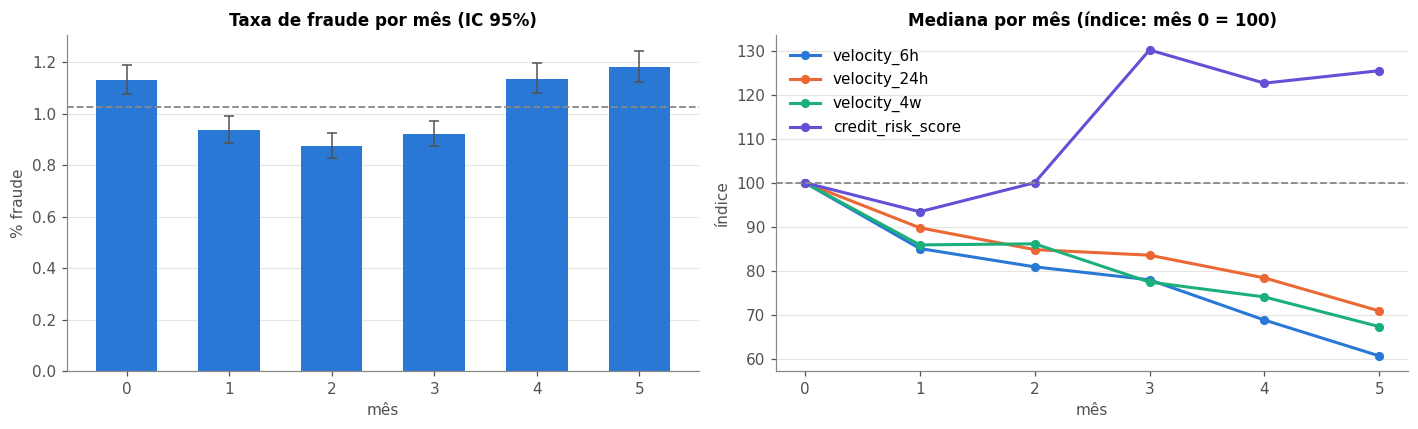

In [18]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

plot_taxa(ax1, por_mes, "Taxa de fraude por mês (IC 95%)", TAXA_BASE)
ax1.set_xlabel("mês")

indice = 100 * medianas / medianas.iloc[0]  # mês 0 = 100: coloca escalas diferentes no mesmo eixo
for c, cor in zip(cols_tempo, [AZUL, LARANJA, VERDE_AGUA, VIOLETA]):
    ax2.plot(indice.index, indice[c], marker="o", ms=5, lw=2, color=cor, label=c)
ax2.axhline(100, color=CINZA, ls="--", lw=1.2)
ax2.set_title("Mediana por mês (índice: mês 0 = 100)")
ax2.set_xlabel("mês")
ax2.set_ylabel("índice")
ax2.legend()

fig.tight_layout()
salvar(fig, "08_drift_temporal")
plt.show()

**Conclusão:**

- A **taxa de fraude varia** entre os meses: de 1,13% (mês 0) cai para 0,87% (mês 2) e sobe até 1,18% (mês 5). Os intervalos de confiança dos meses 2 e 5 não se sobrepõem — a variação é real, não acaso.
- **As três velocidades caem de forma consistente** → **drift gradual**:
  - `velocity_6h`: mediana de 7.623 → 4.621 (**-39%**)
  - `velocity_4w`: 6.344 → 4.267 (**-33%**)
  - `velocity_24h`: 5.950 → 4.215 (**-29%**)

  Nos meses de teste é provável que apareçam valores abaixo da faixa vista no treino — e modelos de árvore não extrapolam.
- `credit_risk_score` muda de patamar entre os meses 2 e 3 (mediana de 106 para 138) → **mudança abrupta de nível**, como uma alteração de política ou de cálculo do score.
- **Decisão de validação:** validação **temporal com janela crescente**, em vez de validação cruzada aleatória:

| Fold | Treina nos meses | Valida no mês |
|---|---|---|
| 1 | 0–2 | 3 |
| 2 | 0–3 | 4 |
| 3 | 0–4 | 5 |

  A média dos 3 folds estima o desempenho; o desvio entre eles mede a estabilidade. O modelo final é treinado nos meses 0–5 e avaliado **uma única vez** nos meses 6–7.
- O efeito do drift das velocidades será medido na modelagem (por exemplo, comparando o desempenho com e sem elas, ou trocando valores absolutos por posições relativas dentro do mês).

## 9. Idade e justiça algorítmica

**Pergunta:** a taxa de fraude difere entre faixas de idade?

O artigo da base propõe avaliar **justiça algorítmica** comparando clientes com **50 anos ou mais** e com **menos de 50**: um modelo justo deveria ter taxas de falso positivo parecidas nos dois grupos — ou seja, não barrar clientes legítimos mais velhos com mais frequência que os mais jovens. Aqui registramos só a taxa de fraude por grupo; a análise de justiça do modelo vem no final do projeto.

In [19]:
grupo_idade = np.where(treino["customer_age"] >= 50, "50 ou mais", "menos de 50")
taxa_por_grupo(treino.assign(grupo_idade=grupo_idade), "grupo_idade")

,qtd,fraudes,% fraude,IC95 inf,IC95 sup
grupo_idade,,,,,
50 ou mais,149234,3296,2.21,2.14,2.28
menos de 50,645755,4855,0.75,0.73,0.77


**Conclusão:**

- Clientes com **50 anos ou mais** fraudam **2,21%**, contra **0,75%** dos com menos de 50 — cerca de **2,9×**. Eles são ~19% do treino (149 mil de 795 mil linhas).
- **Implicação para justiça:** o modelo vai aprender que idade alta indica risco, seja pela própria `customer_age`, seja por variáveis ligadas a ela (`current_address_months_count`, `date_of_birth_distinct_emails_4w`). O risco é **barrar clientes legítimos mais velhos com mais frequência**, ou seja, uma taxa de falso positivo maior para esse grupo.
- **Decisão:** no modelo final, medir a **FPR por grupo de idade** no ponto de operação (5% de FPR global) e reportar a razão entre os grupos. Remover `customer_age` sozinha não resolveria, porque outras variáveis carregam a mesma informação — por isso a medição é feita no resultado, não na entrada.

## 10. Resumo e decisões

| Tema | Achado | Decisão |
|---|---|---|
| Desbalanceamento | Fraude é 1,03% do treino | Métricas: **Recall a 5% de FPR** (principal), PR-AUC e ROC AUC. Acurácia descartada |
| Ausência | Códigos negativos; ausência em `prev_address_months_count` (~4,7×), `intended_balcon_amount` (~2,6×) e `bank_months_count` (~1,8×) associada à fraude | Árvores: manter o código. Lineares: indicador `_ausente` + mediana do treino do fold |
| Valores impossíveis | 20 linhas com `velocity_6h` negativo | Clipar em 0 |
| Coluna constante | `device_fraud_count` | Remover |
| Categóricas | `housing_status = BA` (~3,4×), `employment_status = CC`, `device_os = windows`; categorias raras com ≤ 6 fraudes | Lineares: agrupar raras em `"outros"` + one-hot. LightGBM: categóricas nativas |
| Binárias | Todas com sinal: `has_other_cards = 0` (~2,9×), `keep_alive_session = 0` (~2,6×), `foreign_request = 1` e `phone_home_valid = 0` (~2×) | Usar como estão |
| Numéricas | `proposed_credit_limit` ~2.000 → ~12,5% de fraude; `credit_risk_score` alto, `name_email_similarity` baixo e idade alta → mais fraude; várias relações não lineares | Gradient boosting como modelo principal; SHAP para separar efeitos |
| Assimetria / correlação | Cauda longa em 4 variáveis; só `credit_risk_score` × `proposed_credit_limit` com ρ ≥ 0,5 (0,63) | Lineares: `log1p` + padronização + regularização L2. Nenhuma remoção |
| Drift | Velocidades caem 29–39% em 6 meses; `credit_risk_score` muda de nível no mês 3; taxa de fraude varia entre meses | Validação temporal com janela crescente (3 folds); teste usado uma única vez |
| Idade | ≥ 50 anos: 2,21% vs. 0,75% (~2,9×) | Medir FPR por grupo de idade no modelo final |

**Próximo passo:** `02_baseline.ipynb` — um primeiro modelo simples, avaliado com o esquema de validação acima, que vira a régua para medir as próximas melhorias.